In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Descriptors

df = pd.read_csv("data/dockstring-dataset.tsv", sep="\t")

In [4]:
jak2_lck[["JAK2", "LCK"]].describe()

,JAK2,LCK
count,260153.000000,260151.000000
mean,-8.410401,-8.047818
std,0.971447,0.947048
min,-13.700000,-13.600000
25%,-9.000000,-8.700000
50%,-8.400000,-8.100000
75%,-7.800000,-7.400000
max,-4.000000,-3.800000


In [2]:
jak2_lck = df[["inchikey", "smiles", "JAK2", "LCK"]].copy()

jak2_lck.head()

,inchikey,smiles,JAK2,LCK
0,UMVWYQXKBPJMOF-UHFFFAOYNA-N,C1=C(C2=C(C=C1O)OC(C(C2=O)=O)C3=CC=C(C(=C3)O)O)O,-9.4,-8.1
1,NGOGFTYYXHNFQH-UHFFFAOYNA-N,O=S(=O)(N1CCNCCC1)C2=CC=CC=3C2=CC=NC3,-8.1,-7.8
2,BGVLELSCIHASRV-QPEQYQDCNA-N,C=1C=C2S/C(/N(CC)C2=CC1OC)=C\C(=O)C,-6.6,-6.1
3,KTUFNOKKBVMGRW-RPGFEBOUNA-N,C=1(N=C(C=2C=NC=CC2)C=CN1)NC=3C=C(NC(C4=CC=C(C...,-10.6,-9.3
4,LLJRXVHJOJRCSM-UHFFFAOYNA-N,C1=CC=2C(=CNC2C=C1)C=3C=CN=CC3,-7.9,-6.8


In [3]:
jak2_lck[["JAK2", "LCK"]].isna().sum()

JAK2    2
LCK     4
dtype: int64

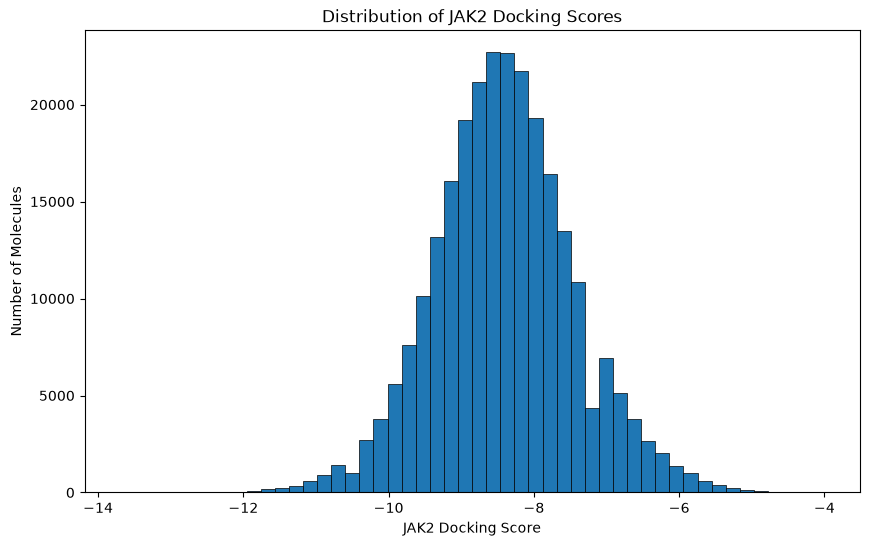

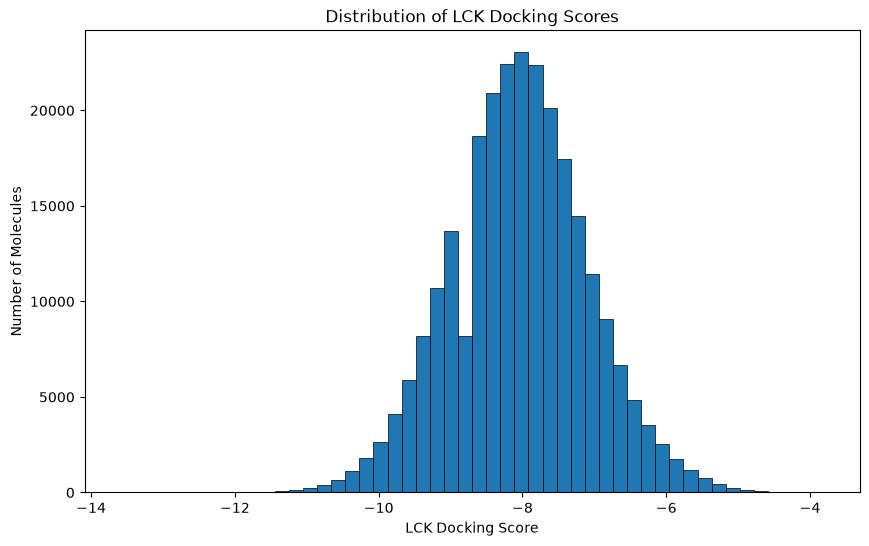

In [5]:
plt.figure(figsize=(10, 6))
plt.hist(jak2_lck["JAK2"].dropna(), bins=50, edgecolor="black", linewidth=0.5)
plt.xlabel("JAK2 Docking Score")
plt.ylabel("Number of Molecules")
plt.title("Distribution of JAK2 Docking Scores")
plt.show()

plt.figure(figsize=(10, 6))
plt.hist(jak2_lck["LCK"].dropna(), bins=50, edgecolor="black", linewidth=0.5)
plt.xlabel("LCK Docking Score")
plt.ylabel("Number of Molecules")
plt.title("Distribution of LCK Docking Scores")
plt.show()

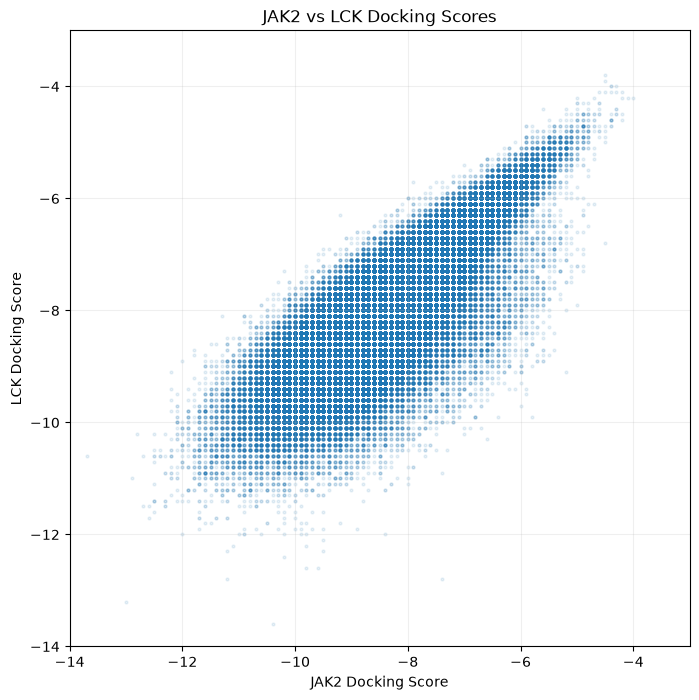

In [6]:
plt.figure(figsize=(8, 8))

plt.scatter(
    jak2_lck["JAK2"],
    jak2_lck["LCK"],
    alpha=0.1,
    s=4
)

plt.xlabel("JAK2 Docking Score")
plt.ylabel("LCK Docking Score")
plt.title("JAK2 vs LCK Docking Scores")
plt.xlim(-14, -3)
plt.ylim(-14, -3)
plt.grid(alpha=0.2)

plt.show()

In [7]:
jak2_lck[["JAK2", "LCK"]].corr()

,JAK2,LCK
JAK2,1.000000,0.803122
LCK,0.803122,1.000000


In [ ]:
#docking scores are more favorable when more negative
jak2_lck["score_difference"] = jak2_lck["JAK2"] - jak2_lck["LCK"]
jak2_lck.sort_values("score_difference").head(10)

,inchikey,smiles,JAK2,LCK,score_difference
188364,IDPUFKCIPCGYIL-UHFFFAOYNA-N,OC(CC1C2(C1)C=3C(C4=NC=CC=C24)=CC=CC3)(C5=CC=C...,-11.3,-8.1,-3.2
23648,KPZQRBACZSLMPH-PMERELPUNA-N,O1C=2C(=C(C(O)=C(C2C)C)C)CC[C@]1(CN3CCN(C4=NC(...,-11.8,-8.7,-3.1
24653,SQTNIIDYSRRCTE-UHFFFAOYNA-N,O=C1N(C=2C=3C(C4=C(C2)C=5C(C=C4)=CC=CC5)=CC=CC...,-13.7,-10.6,-3.1
77550,GQZDURBFXSVNIJ-UHFFFAOYNA-N,C1=C2C(=C(C=3C1=CC=CC3)C4=NNC(C4)C5=CC=C(C=C5)...,-12.2,-9.1,-3.1
100677,OQQZSNNSAXZWOI-APHBZQTQNA-N,C=1C=2C(=CNC2C(=CC1)C=3C(=CC4=C(/C(/CC(N4)(C)C...,-12.0,-8.9,-3.1
165551,VAZORWJPDVEPEX-BIOUEDRUNA-O,[S+](O)(=O)(N1CCN(C2=NC(=NC3=C2C=CC=C3)C4=CN=C...,-11.8,-8.8,-3.0
79062,HBWIHBZMLROJND-DOEITSDWNA-O,[S+](O)(=O)(N1CCN(C2=NC(=NC3=C2C=CC=C3)C4=CC=C...,-11.5,-8.6,-2.9
108326,LERYJFJOWCFHBL-QGZVFWFLNA-N,O1C2=C(C3=C(C=4C(C(=C3[C@H]1COCC=5C=CC=CC5)O)=...,-10.2,-7.3,-2.9
22221,GVJALQHQZPOADA-YIOWICSRNA-N,C=1C=C([C@@H](O)CNCCC2=CC=CC(=C2)CNCCCC3=CC=CC...,-9.2,-6.3,-2.9
76072,HZPMXBJBHJVLLP-LNNLXFCONA-N,N1(C=C(CCN(CCN2C(NCC2)=O)C)C=3C1=CC=C(Cl)C3)C4...,-10.3,-7.5,-2.8


In [10]:
mol = df["smiles"].apply(Chem.MolFromSmiles)
mol.head()

0    <rdkit.Chem.rdchem.Mol object at 0x1521be9a9a80>
1    <rdkit.Chem.rdchem.Mol object at 0x1521be9a99a0>
2    <rdkit.Chem.rdchem.Mol object at 0x1521be9a9c40>
3    <rdkit.Chem.rdchem.Mol object at 0x1521be9aa030>
4    <rdkit.Chem.rdchem.Mol object at 0x1521be9a9620>
Name: smiles, dtype: object

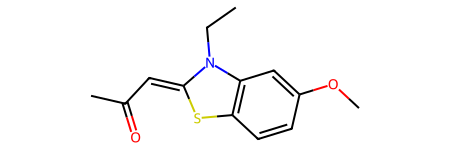

In [12]:
mol.iloc[2]

In [14]:
jak2_lck["MolWt"] = mol.apply(Descriptors.MolWt)

In [16]:
jak2_lck[["smiles","MolWt"]].head()

,smiles,MolWt
0,C1=C(C2=C(C=C1O)OC(C(C2=O)=O)C3=CC=C(C(=C3)O)O)O,302.238
1,O=S(=O)(N1CCNCCC1)C2=CC=CC=3C2=CC=NC3,291.376
2,C=1C=C2S/C(/N(CC)C2=CC1OC)=C\C(=O)C,249.335
3,C=1(N=C(C=2C=NC=CC2)C=CN1)NC=3C=C(NC(C4=CC=C(C...,493.615
4,C1=CC=2C(=CNC2C=C1)C=3C=CN=CC3,194.237


In [17]:
jak2_lck["LogP"] =mol.apply(Descriptors.MolLogP)

In [20]:
jak2_lck[["LogP"]].head()

,LogP
0,1.39450
1,1.21880
2,3.05760
3,4.59032
4,3.22990


In [21]:
#TPSA (Topological Polar Surface Area) measures roughly how much polar surface a molecule has. 
# It's related to things like membrane permeability and absorption.

jak2_lck["TPSA"] = mol.apply(Descriptors.TPSA)

In [22]:
jak2_lck[["TPSA"]].head()

,TPSA
0,124.29
1,62.30
2,29.54
3,86.28
4,28.68


In [23]:
#HBD → hydrogen-bond donors
#HBA → hydrogen-bond acceptors

jak2_lck["HBD"] = mol.apply(Descriptors.NumHDonors)
jak2_lck["HBA"] = mol.apply(Descriptors.NumHAcceptors)

In [24]:
jak2_lck[["HBD", "HBA"]].head()

,HBD,HBA
0,4,7
1,1,4
2,0,4
3,2,7
4,1,1


Rotatable bonds measure molecular flexibility. More rotatable bonds generally means the molecule can adopt more conformations.

Ring count tells us how many rings are in the molecular structure.



In [26]:
jak2_lck["RotBonds"] = mol.apply(Descriptors.NumRotatableBonds)
jak2_lck["Rings"] = mol.apply(Descriptors.RingCount)

In [27]:
jak2_lck[["RotBonds","Rings"]].head()

,RotBonds,Rings
0,1,3
1,2,3
2,3,2
3,7,5
4,1,3


In [35]:
features = ["MolWt", "LogP", "TPSA", "HBD", "HBA", "RotBonds", "Rings"]
d2 = jak2_lck[features+["JAK2", "LCK", "score_difference"]].corr()

d2


,MolWt,LogP,TPSA,HBD,HBA,RotBonds,Rings,JAK2,LCK,score_difference
MolWt,1.000000,0.363050,0.582047,0.367905,0.567837,0.686629,0.546710,-0.381073,-0.476819,0.135152
LogP,0.363050,1.000000,-0.328720,-0.180994,-0.205795,0.148332,0.447584,-0.355836,-0.454197,0.140217
TPSA,0.582047,-0.328720,1.000000,0.696940,0.768672,0.517668,0.098740,-0.130791,-0.129165,-0.007828
HBD,0.367905,-0.180994,0.696940,1.000000,0.354407,0.398368,-0.001959,-0.098544,-0.066326,-0.054627
HBA,0.567837,-0.205795,0.768672,0.354407,1.000000,0.478787,0.243857,-0.091185,-0.095293,0.002793
RotBonds,0.686629,0.148332,0.517668,0.398368,0.478787,1.000000,0.038275,0.029512,0.038227,-0.012516
Rings,0.546710,0.447584,0.098740,-0.001959,0.243857,0.038275,1.000000,-0.632541,-0.736599,0.137984
JAK2,-0.381073,-0.355836,-0.130791,-0.098544,-0.091185,0.029512,-0.632541,1.000000,0.803122,0.350043
LCK,-0.476819,-0.454197,-0.129165,-0.066326,-0.095293,0.038227,-0.736599,0.803122,1.000000,-0.276991
score_difference,0.135152,0.140217,-0.007828,-0.054627,0.002793,-0.012516,0.137984,0.350043,-0.276991,1.000000


In [ ]:
# Correlation values for JAK2, LCK, and score_difference
d2[["JAK2", "LCK", "score_difference"]]

,JAK2,LCK,score_difference
MolWt,-0.381073,-0.476819,0.135152
LogP,-0.355836,-0.454197,0.140217
TPSA,-0.130791,-0.129165,-0.007828
HBD,-0.098544,-0.066326,-0.054627
HBA,-0.091185,-0.095293,0.002793
RotBonds,0.029512,0.038227,-0.012516
Rings,-0.632541,-0.736599,0.137984
JAK2,1.000000,0.803122,0.350043
LCK,0.803122,1.000000,-0.276991
score_difference,0.350043,-0.276991,1.000000
